# 03 — Perfis de imóveis com K-Means de raiz
Esta análise é distinta da criação de ClassePreco: aqui usamos características das casas,
sem Price, para explorar perfis. O K-Means e a silhouette são implementados em libs/.

As classes de preço do notebook 02 usam scikit-learn por orientação recebida; o algoritmo
deste notebook mantém a implementação de raiz prevista no guião.

In [1]:
from pathlib import Path
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython import get_ipython
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from libs.data import load_housing, PRICE_LABELS, FEATURES, prepare_partitions, HousingPreparation

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("svg")
SEED = 42
houses = load_housing(download=True)
print(houses.attrs["source"])
print({"Python": platform.python_version(), "pandas": pd.__version__, "NumPy": np.__version__, "scikit-learn": sklearn.__version__})

{'dataset': 'dansbecker/melbourne-housing-snapshot', 'ficheiro': 'melb_data.csv', 'sha256': '3e449c3e95088da8a3a6b10331a5703f2c951d0740f317f97ed9baf0db1fd9f8', 'linhas_originais': 13580, 'duplicados_exatos_removidos': 0, 'preços_inválidos_removidos': 0, 'linhas_utilizadas': 13580}
{'Python': '3.11.6', 'pandas': '3.0.1', 'NumPy': '1.26.4', 'scikit-learn': '1.8.0'}


## Preparação e comparação de K
A análise é descritiva na base completa. Aplicamos log1p às áreas e normalizamos todas
as entradas para reduzir o domínio de escalas diferentes. A codificação do tipo é one-hot.
Price e classes derivadas não entram na matriz.

A silhouette usa a mesma amostra aleatória de até 500 pontos em todos os K.
Não interpretamos automaticamente estes clusters como classes de preço.

,inertia,silhouette_amostra,iterações,convergiu
K,,,,
2,125207.854301,0.284426,13,True
3,107147.026484,0.325366,12,True
4,92568.298075,0.254718,32,True
5,84934.527209,0.218304,53,True
6,79000.186095,0.220436,35,True


K candidato pela silhouette amostral: 3


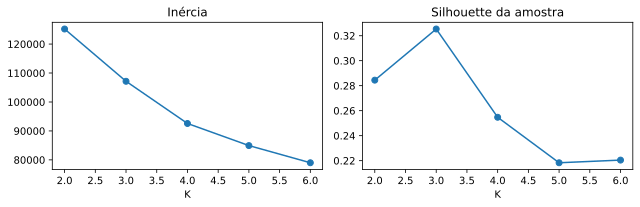

In [2]:
from libs.kmeans import KMeans
from libs.metrics import silhouette_score

preparation = HousingPreparation(scale=True, log_areas=True).fit(houses)
X = preparation.transform(houses)
evaluation = np.random.default_rng(SEED).choice(len(X), size=min(500, len(X)), replace=False)
models, results = {}, []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=5, max_iter=100, seed=SEED).fit(X)
    models[k] = model
    try:
        score = silhouette_score(X[evaluation], model.labels_[evaluation])
    except ValueError:
        score = np.nan
    results.append({
        "K": k, "inertia": model.inertia_, "silhouette_amostra": score,
        "iterações": model.n_iter_, "convergiu": model.converged_,
    })
summary = pd.DataFrame(results).set_index("K")
display(summary)
valid = summary.loc[summary["convergiu"], "silhouette_amostra"].dropna()
if valid.empty:
    raise RuntimeError("Sem solução convergente e silhouette válida; rever a configuração.")
candidate_k = int(valid.idxmax())
print("K candidato pela silhouette amostral:", candidate_k)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
summary["inertia"].plot(marker="o", ax=axes[0], title="Inércia")
summary["silhouette_amostra"].plot(marker="o", ax=axes[1], title="Silhouette da amostra")
plt.tight_layout()
plt.show()

## Perfis e sensibilidade à inicialização
Os grupos são descritos nas unidades originais. Price é consultado apenas depois de formar
os grupos. Comparamos também inércia e silhouette em sementes adicionais; isto não é,
por si só, uma prova de estabilidade de todas as atribuições individuais.

In [3]:
profile = houses.assign(cluster=models[candidate_k].labels_)
numeric = [name for name in FEATURES if name != "Type"] + ["Price"]
display(profile.groupby("cluster")[numeric].median())
display(pd.crosstab(profile["cluster"], profile["Type"], normalize="index"))
display(profile.groupby("cluster").size().rename("casas"))
stability = []
for seed in [SEED, SEED + 1, SEED + 2]:
    model = models[candidate_k] if seed == SEED else KMeans(candidate_k, n_init=5, seed=seed).fit(X)
    stability.append({
        "semente": seed, "inertia": model.inertia_, "convergiu": model.converged_,
        "silhouette_amostra": silhouette_score(X[evaluation], model.labels_[evaluation]),
    })
display(pd.DataFrame(stability))
reports = Path("reports")
reports.mkdir(exist_ok=True)
summary.to_csv(reports / "housing_clusters.csv")
pd.DataFrame(stability).to_csv(reports / "housing_cluster_stability.csv", index=False)

,Rooms,Distance,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Price
cluster,,,,,,,,,,
0,2.0,6.9,1.0,1.0,0.0,74.0,1975.0,-37.825650,144.99720,560000.0
1,3.0,10.4,1.0,2.0,561.0,145.0,1960.0,-37.793555,145.00202,1080500.0
2,3.0,9.9,2.0,2.0,198.5,130.0,2005.0,-37.802695,145.00350,846750.0


Type,h,t,u
cluster,,,
0,0.011475,0.0,0.988525
1,0.999788,0.0,0.000212
2,0.000000,1.0,0.000000


cluster
0    3050
1    9416
2    1114
Name: casas, dtype: int64

,semente,inertia,convergiu,silhouette_amostra
0,42,107147.026484,True,0.325366
1,43,107147.026484,True,0.325366
2,44,107147.026484,True,0.325366


## Limitações
A escolha de K deve considerar também tamanhos e interpretação dos grupos.
Escalas, áreas atípicas, imputação e o peso das colunas one-hot podem alterar os resultados.
Um cluster com preço mediano maior não foi necessariamente formado por causa do preço.

## Interpretação desta execução
Entre K=2 e K=6, K=3 obteve a maior silhouette amostral (0,3254). As três sementes avaliadas produziram a mesma inércia e a mesma silhouette nesta experiência, o que não prova estabilidade sob outras escolhas de variáveis ou preparação.

O grupo 0 contém 3 050 imóveis, dos quais cerca de 98,85% são do tipo u; o grupo 1 contém 9 416, quase todos do tipo h; o grupo 2 contém 1 114, todos do tipo t. Os grupos quase reproduzem Type. Isto evidencia o peso da codificação dessa variável, em vez de demonstrar a descoberta de três níveis de preço.

As medianas de Price são 560 000, 1 080 500 e 846 750, respetivamente, consultadas apenas após formar os grupos. Estes números não devem ser confundidos com os centroides das classes barato/normal/caro do notebook 02.